Experiment 6: Transfer Learning with VGG16

Aim: Use a pretrained CNN and train a new classifier for the image categories in your dataset.

Important: The manual calls this object detection, but its VGG16/ImageFolder steps classify the whole image into one category. This notebook follows those prescribed classification steps; it does not draw bounding boxes.

Dataset: Caltech-101 or another image dataset arranged in one folder per class.

In [2]:
from pathlib import Path
source_dir = Path(r"D:\dl\caltech-101\caltech-101\101_ObjectCategories")

1. Import packages and check the dataset

In [5]:

import random
import shutil
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('PyTorch:', torch.__version__)
print('Torchvision:', __import__('torchvision').__version__)
print('Device:', 'CUDA GPU' if torch.cuda.is_available() else 'CPU')

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: CPU


In [12]:
# Change this path to the extracted category-folder dataset.
source_dir = Path(r'D:\dl\caltech-101\caltech-101\101_ObjectCategories')
split_dir = Path(r'D:\dl\caltech-101\caltech_small_split')

if not source_dir.exists():
    raise FileNotFoundError(
        f'Cannot find {source_dir}. Extract the dataset into that folder, '
        'or change source_dir to your dataset location.'
    )

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp'}
class_folders = sorted([p for p in source_dir.iterdir() if p.is_dir() and p.name != 'BACKGROUND_Google'])[:5]
print('Classes found:', len(class_folders))
for folder in class_folders[:10]:
    count = sum(1 for p in folder.iterdir() if p.suffix.lower() in image_extensions)
    print(f'{folder.name}: {count} images')
if len(class_folders) == 0:
    raise ValueError('No class subfolders found. Put images inside one folder per class.')

Classes found: 5
accordion: 55 images
airplanes: 800 images
anchor: 42 images
ant: 42 images
barrel: 47 images



2. Split the dataset into train, validation, and test

This creates a 50% / 25% / 25% split within each class. The source dataset is left unchanged.

In [16]:
random.seed(42)

for split in ('train', 'valid', 'test'):
    (split_dir / split).mkdir(parents=True, exist_ok=True)

for class_folder in class_folders:
    images = sorted([p for p in class_folder.iterdir() if p.suffix.lower() in image_extensions])
    random.shuffle(images)
    images = images[:40]  # Quick run: use at most 40 images per class
    if len(images) < 4:
        print(f'Skipping {class_folder.name}: fewer than 4 images')
        continue

    train_images, remaining = train_test_split(images, train_size=0.5, random_state=42)
    valid_images, test_images = train_test_split(remaining, train_size=0.5, random_state=42)

    for split_name, split_images in [('train', train_images), ('valid', valid_images), ('test', test_images)]:
        destination = split_dir / split_name / class_folder.name
        destination.mkdir(parents=True, exist_ok=True)
        for image_path in split_images:
            shutil.copy2(image_path, destination / image_path.name)

print('Dataset split saved to:', split_dir.resolve())

Dataset split saved to: D:\dl\caltech-101\caltech_small_split


3. Preprocess images and create data loaders

Training uses random augmentation. Validation and test images use resizing and center cropping only.

In [17]:
image_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomRotation(15),
        transforms.ColorJitter(),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    'eval': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}

image_datasets = {
    'train': datasets.ImageFolder(split_dir / 'train', transform=image_transforms['train']),
    'valid': datasets.ImageFolder(split_dir / 'valid', transform=image_transforms['eval']),
    'test': datasets.ImageFolder(split_dir / 'test', transform=image_transforms['eval']),
}

class_names = image_datasets['train'].classes
for split_name, dataset in image_datasets.items():
    if dataset.classes != class_names:
        raise ValueError(f'{split_name} classes do not match training classes')
    print(f'{split_name}: {len(dataset)} images; classes: {len(dataset.classes)}')

batch_size = 16
loaders = {
    split: DataLoader(dataset, batch_size=batch_size, shuffle=(split == 'train'), num_workers=0)
    for split, dataset in image_datasets.items()
}
print('Class names:', class_names)

train: 542 images; classes: 5
valid: 283 images; classes: 5
test: 290 images; classes: 5
Class names: ['accordion', 'airplanes', 'anchor', 'ant', 'barrel']


4. Load pretrained VGG16 and replace the classifier

The convolutional feature extractor is frozen. A new classifier is added for the classes in this dataset.

In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

try:
    weights = models.VGG16_Weights.DEFAULT
    model = models.vgg16(weights=weights)
except AttributeError:  # Compatibility with older torchvision versions
    model = models.vgg16(pretrained=True)

for parameter in model.parameters():
    parameter.requires_grad = False

input_features = model.classifier[6].in_features
model.classifier[6] = nn.Sequential(
    nn.Linear(input_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, len(class_names)),
    nn.LogSoftmax(dim=1)
)

model = model.to(device)
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.classifier[6].parameters(), lr=0.001)
print('Using device:', device)
print('Number of classes:', len(class_names))
print(model.classifier[6])

Using device: cpu
Number of classes: 5
Sequential(
  (0): Linear(in_features=4096, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=5, bias=True)
  (4): LogSoftmax(dim=1)
)


5. Train the classifier with early stopping

The best validation-loss model is saved. Training stops if validation loss does not improve for two consecutive epochs.

In [19]:
num_epochs = 3
patience = 1
best_val_loss = float('inf')
best_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0
history = {'train_loss': [], 'train_accuracy': [], 'valid_loss': [], 'valid_accuracy': []}

for epoch in range(num_epochs):
    print(f'\nEpoch {epoch + 1}/{num_epochs}')
    for phase in ('train', 'valid'):
        model.train(phase == 'train')
        total_loss = 0.0
        all_predictions = []
        all_labels = []

        for images, labels in loaders[phase]:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(images)
                loss = criterion(outputs, labels)
                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            total_loss += loss.item() * labels.size(0)
            all_predictions.extend(outputs.argmax(dim=1).detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

        epoch_loss = total_loss / len(image_datasets[phase])
        epoch_accuracy = accuracy_score(all_labels, all_predictions)
        history[f'{phase}_loss'].append(epoch_loss)
        history[f'{phase}_accuracy'].append(epoch_accuracy)
        print(f'{phase.capitalize()} loss: {epoch_loss:.4f} | accuracy: {epoch_accuracy:.4f}')

        if phase == 'valid':
            if epoch_loss < best_val_loss:
                best_val_loss = epoch_loss
                best_weights = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print('Early stopping: validation loss did not improve.')
        break

model.load_state_dict(best_weights)


Epoch 1/3
Train loss: 0.4525 | accuracy: 0.8635
Valid loss: 0.0488 | accuracy: 0.9929

Epoch 2/3
Train loss: 0.0484 | accuracy: 0.9871
Valid loss: 0.0185 | accuracy: 0.9965

Epoch 3/3
Train loss: 0.1053 | accuracy: 0.9576
Valid loss: 0.0200 | accuracy: 0.9929
Early stopping: validation loss did not improve.


<All keys matched successfully>

6. Evaluate on test images

In [20]:
model.eval()
test_predictions = []
test_labels = []

with torch.no_grad():
    for images, labels in loaders['test']:
        outputs = model(images.to(device))
        test_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        test_labels.extend(labels.numpy())

test_accuracy = accuracy_score(test_labels, test_predictions)
print(f'Test accuracy: {test_accuracy:.4f}')
print('\nClassification report:')
print(classification_report(test_labels, test_predictions, target_names=class_names, zero_division=0))
print('Confusion matrix:')
print(confusion_matrix(test_labels, test_predictions))

torch.save({'model_state': model.state_dict(), 'classes': class_names}, 'experiment06_vgg16.pth')
print('Saved model to experiment06_vgg16.pth')

Test accuracy: 0.9966

Classification report:
              precision    recall  f1-score   support

   accordion       1.00      1.00      1.00        21
   airplanes       1.00      1.00      1.00       209
      anchor       0.95      1.00      0.97        18
         ant       1.00      1.00      1.00        20
      barrel       1.00      1.00      1.00        22

    accuracy                           1.00       290
   macro avg       0.99      1.00      0.99       290
weighted avg       1.00      1.00      1.00       290

Confusion matrix:
[[ 21   0   0   0   0]
 [  0 208   1   0   0]
 [  0   0  18   0   0]
 [  0   0   0  20   0]
 [  0   0   0   0  22]]
Saved model to experiment06_vgg16.pth


7. Plot training and validation curves

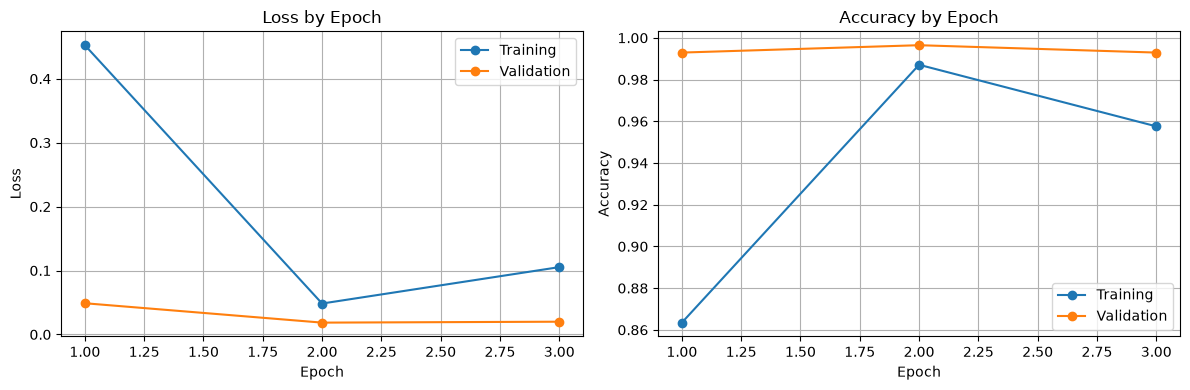

In [21]:
epochs_ran = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, history['train_loss'], marker='o', label='Training')
axes[0].plot(epochs_ran, history['valid_loss'], marker='o', label='Validation')
axes[0].set_title('Loss by Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_ran, history['train_accuracy'], marker='o', label='Training')
axes[1].plot(epochs_ran, history['valid_accuracy'], marker='o', label='Validation')
axes[1].set_title('Accuracy by Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Result

The pretrained VGG16 model was adapted to the image categories and evaluated on the held-out test set. Record the final test accuracy and classification report above.

Dataset reminder: The manual’s workflow is image classification with one label per image. True object detection requires bounding-box labels and a detection model.